<a href="https://colab.research.google.com/github/CheredlaJasvina/DSA0302-NLP/blob/main/DSA0302_AT_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Task 10

In [5]:
import nltk

grammar = nltk.CFG.fromstring("""
S -> NP VP
NP -> Det N
NP -> Det Adj N
NP -> NP PP
VP -> V
VP -> V NP
VP -> VP PP
PP -> P NP

Det -> 'the' | 'a'
N -> 'student' | 'students' | 'form' | 'timetable' | 'notice'
V -> 'checks' | 'check' | 'submits' | 'show'
Adj -> 'late'
P -> 'with' | 'near' | 'in'
""")

print(grammar)

Grammar with 23 productions (start state = S)
    S -> NP VP
    NP -> Det N
    NP -> Det Adj N
    NP -> NP PP
    VP -> V
    VP -> V NP
    VP -> VP PP
    PP -> P NP
    Det -> 'the'
    Det -> 'a'
    N -> 'student'
    N -> 'students'
    N -> 'form'
    N -> 'timetable'
    N -> 'notice'
    V -> 'checks'
    V -> 'check'
    V -> 'submits'
    V -> 'show'
    Adj -> 'late'
    P -> 'with'
    P -> 'near'
    P -> 'in'


In [6]:
from nltk import CFG
from nltk.parse import RecursiveDescentParser

topdown_grammar = CFG.fromstring("""
S -> NP VP
NP -> Det N | Det Adj N | Det N PP
VP -> V | V NP | V NP PP
PP -> P NP

Det -> 'the' | 'a'
N -> 'student' | 'students' | 'form' | 'timetable' | 'notice'
V -> 'checks' | 'check' | 'submits' | 'show'
Adj -> 'late'
P -> 'with' | 'near' | 'in'
""")

parser = RecursiveDescentParser(topdown_grammar)

sentence = "the student checks the timetable"
tokens = sentence.split()

print("Top-Down Parser Results:")

for tree in parser.parse(tokens):
    print(tree)
    tree.pretty_print()

Top-Down Parser Results:
(S
  (NP (Det the) (N student))
  (VP (V checks) (NP (Det the) (N timetable))))
                  S                     
      ____________|_____                 
     |                  VP              
     |             _____|___             
     NP           |         NP          
  ___|_____       |      ___|______      
Det        N      V    Det         N    
 |         |      |     |          |     
the     student checks the     timetable



In [7]:
from nltk.parse import EarleyChartParser

earley_grammar = CFG.fromstring("""
S -> NP VP
NP -> Det N | Det Adj N | NP PP
VP -> V | V NP | VP PP
PP -> P NP

Det -> 'the' | 'a'
N -> 'student' | 'students' | 'form' | 'timetable' | 'notice'
V -> 'checks' | 'check' | 'submits' | 'show'
Adj -> 'late'
P -> 'with' | 'near' | 'in'
""")

earley_parser = EarleyChartParser(earley_grammar)

sentence = "the student checks the timetable"
tokens = sentence.split()

print("Earley Parser Results:")

for tree in earley_parser.parse(tokens):
    print(tree)
    tree.pretty_print()

Earley Parser Results:
(S
  (NP (Det the) (N student))
  (VP (V checks) (NP (Det the) (N timetable))))
                  S                     
      ____________|_____                 
     |                  VP              
     |             _____|___             
     NP           |         NP          
  ___|_____       |      ___|______      
Det        N      V    Det         N    
 |         |      |     |          |     
the     student checks the     timetable



In [8]:
from nltk import PCFG
from nltk.parse import ViterbiParser

pcfg_grammar = PCFG.fromstring("""
S -> NP VP [1.0]

NP -> Det N [0.5] | Det Adj N [0.3] | Det N PP [0.2]
VP -> V [0.2] | V NP [0.5] | V NP PP [0.3]
PP -> P NP [1.0]

Det -> 'the' [0.7] | 'a' [0.3]
N -> 'student' [0.3] | 'students' [0.1] | 'form' [0.2] | 'timetable' [0.2] | 'notice' [0.2]
V -> 'checks' [0.3] | 'check' [0.2] | 'submits' [0.3] | 'show' [0.2]
Adj -> 'late' [1.0]
P -> 'with' [0.4] | 'near' [0.3] | 'in' [0.3]
""")

viterbi_parser = ViterbiParser(pcfg_grammar)

sentence = "the student checks the timetable"
tokens = sentence.split()

print("PCFG Viterbi Parser Results:")

for tree in viterbi_parser.parse(tokens):
    print(tree)
    print("Probability:", tree.prob())

PCFG Viterbi Parser Results:
(S
  (NP (Det the) (N student))
  (VP (V checks) (NP (Det the) (N timetable)))) (p=0.0011025)
Probability: 0.0011024999999999997


In [9]:
def feature_check(sentence):
    words = sentence.lower().split()

    subject = None
    verb = None

    if "students" in words:
        subject = "plural"
    elif "student" in words:
        subject = "singular"

    for word in words:
        if word in ["checks", "check", "submits", "show"]:
            verb = word
            break

    if subject == "plural" and verb in ["checks", "submits"]:
        return "Subject-Verb Agreement Error"

    if subject == "singular" and verb in ["check", "show"]:
        return "Subject-Verb Agreement Error"

    if verb in ["checks", "check", "submits", "show"]:
        verb_index = words.index(verb)

        if verb_index == len(words) - 1:
            return "Missing Object"

    return "No Error Detected"


print(feature_check("the student checks the timetable"))
print(feature_check("the students checks the timetable"))
print(feature_check("the student submits"))

No Error Detected
Subject-Verb Agreement Error
Missing Object


In [10]:
sentences = [
    "the student checks the timetable",
    "the student submits the form",
    "the students check the notice",
    "the student checks the notice",
    "the student submits a form",
    "the students show the timetable",
    "the late student checks the timetable",
    "a student submits the form",
    "the student checks a notice",
    "the students check the timetable",

    "the student checks the form",
    "a student checks the notice",
    "the late student submits the form",
    "the student checks the timetable with a student",
    "the student checks the notice near the form",
    "the student checks the timetable in the notice",
    "the student with the notice checks the timetable",
    "the student near the form checks the notice",
    "the student checks",
    "the students checks the timetable",

    "the student check the timetable",
    "the student submits",
    "the students submits the form",
    "the notice checks the student",
    "the form submits the student",
    "the student show the form",
    "the late students check the notice",
    "the student checks the late notice",
    "a student checks a timetable",
    "the student checks the timetable with a student near the form"
]

print("Total Sentences:", len(sentences))

Total Sentences: 30


In [11]:
import time
import pandas as pd
import matplotlib.pyplot as plt

results = []

topdown_times = []
earley_times = []
pcfg_times = []
earley_states = []

for number, sentence in enumerate(sentences, 1):

    tokens = sentence.split()

    # Top-Down Parser
    start = time.perf_counter()
    topdown_trees = list(parser.parse(tokens))
    topdown_time = (time.perf_counter() - start) * 1000

    # Earley Parser
    start = time.perf_counter()
    chart = earley_parser.chart_parse(tokens)
    earley_trees = list(chart.parses(earley_grammar.start()))
    earley_time = (time.perf_counter() - start) * 1000

    # PCFG Viterbi Parser
    start = time.perf_counter()
    pcfg_trees = list(viterbi_parser.parse(tokens))
    pcfg_time = (time.perf_counter() - start) * 1000

    # Store execution times
    topdown_times.append(topdown_time)
    earley_times.append(earley_time)
    pcfg_times.append(pcfg_time)

    # Store Earley chart states
    states = chart.num_edges()
    earley_states.append(states)

    # Store results
    results.append({
        "Sentence No.": number,
        "Sentence": sentence,
        "Words": len(tokens),
        "Top-Down Parses": len(topdown_trees),
        "Earley Parses": len(earley_trees),
        "PCFG Parses": len(pcfg_trees),
        "Earley States": states,
        "Top-Down Time (ms)": round(topdown_time, 4),
        "Earley Time (ms)": round(earley_time, 4),
        "PCFG Time (ms)": round(pcfg_time, 4),
        "Feature Check": feature_check(sentence)
    })

# Create results table
df = pd.DataFrame(results)

print("PARSER PERFORMANCE RESULTS")
display(df)

# Save results
df.to_csv("parser_results.csv", index=False)
print("Results saved as parser_results.csv")

PARSER PERFORMANCE RESULTS


,Sentence No.,Sentence,Words,Top-Down Parses,Earley Parses,PCFG Parses,Earley States,Top-Down Time (ms),Earley Time (ms),PCFG Time (ms),Feature Check
0,1,the student checks the timetable,5,1,1,1,44,9.1968,3.4989,3.2738,No Error Detected
1,2,the student submits the form,5,1,1,1,44,19.0160,1.6023,2.8684,No Error Detected
2,3,the students check the notice,5,1,1,1,44,9.7740,5.8705,1.4630,No Error Detected
3,4,the student checks the notice,5,1,1,1,44,18.1646,1.7101,4.8210,No Error Detected
4,5,the student submits a form,5,1,1,1,44,7.0588,3.0558,2.3523,No Error Detected
5,6,the students show the timetable,5,1,1,1,44,6.0725,2.0030,1.5063,No Error Detected
6,7,the late student checks the timetable,6,1,1,1,48,5.4453,2.0548,1.8050,No Error Detected
7,8,a student submits the form,5,1,1,1,44,5.3438,1.7443,1.4011,No Error Detected
8,9,the student checks a notice,5,1,1,1,44,7.6425,3.1125,1.0657,No Error Detected
9,10,the students check the timetable,5,1,1,1,44,3.2947,1.0547,0.7998,No Error Detected


Results saved as parser_results.csv


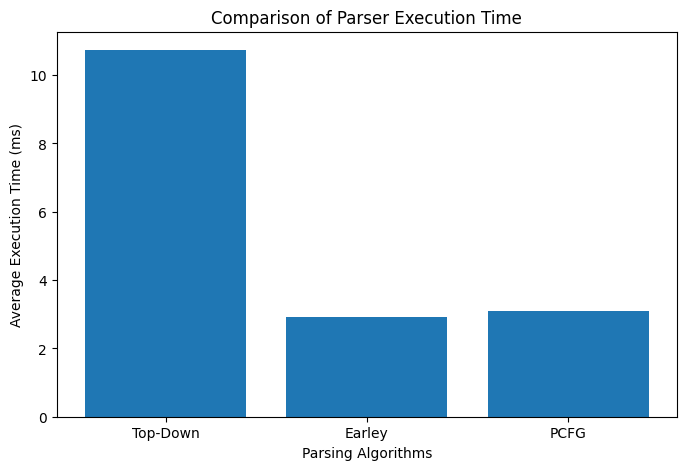

In [12]:
average_times = [
    sum(topdown_times) / len(topdown_times),
    sum(earley_times) / len(earley_times),
    sum(pcfg_times) / len(pcfg_times)
]

plt.figure(figsize=(8, 5))

plt.bar(
    ["Top-Down", "Earley", "PCFG"],
    average_times
)

plt.xlabel("Parsing Algorithms")
plt.ylabel("Average Execution Time (ms)")
plt.title("Comparison of Parser Execution Time")

plt.show()

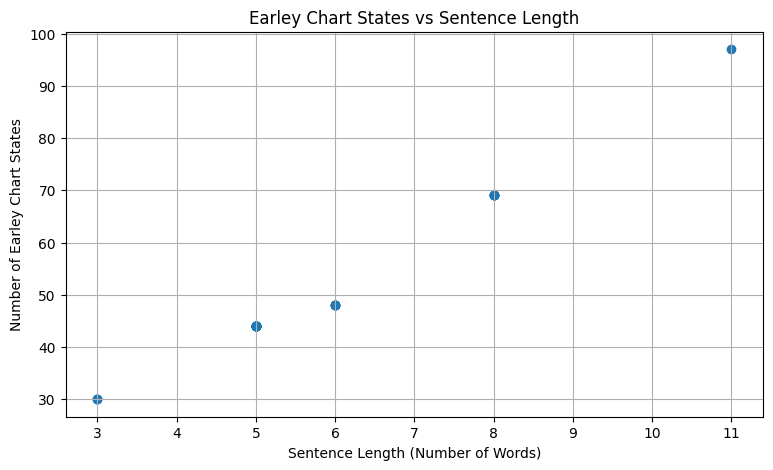

In [13]:
plt.figure(figsize=(9, 5))

plt.scatter(df["Words"], df["Earley States"])

plt.xlabel("Sentence Length (Number of Words)")
plt.ylabel("Number of Earley Chart States")
plt.title("Earley Chart States vs Sentence Length")

plt.grid(True)
plt.show()